# Exerciţiu laborator 7
## Inferenţă Bayesiană cu PyMC

Un cercetător măsoară nivelul de zgomot ambiental în diferite locaţii dintr-un oraş. El suspectează că nivelul de zgomot, notat $X$, urmează o distribuţie normală, dar atât media $\mu$, cât şi deviaţia standard $\sigma$ sunt necunoscute.

Cercetătorul are 10 observaţii ale nivelului de zgomot (în decibeli, dB):

$$56, 60, 58, 55, 57, 59, 61, 56, 58, 60.$$

Scopul este să folosim inferenţa Bayesiană pentru a estima pe $\mu$ şi pe $\sigma$.

a) Definiţi un model în PyMC pentru această problemă. Puteţi alege ca distribuţii a priori $\mu \sim \mathcal{N}(x, 10^2)$ şi $\sigma \sim \text{HalfNormal}(10)$. Cât ar trebui să fie $x$?

Fie $x_1, \dots, x_n$ observaţiile, cu $n = 10$. Modelul este:

$$
\begin{align*}
\mu &\sim \mathcal{N}(x, 10^2) \\
\sigma &\sim \text{HalfNormal}(10) \\
X_i | \mu, \sigma &\sim \mathcal{N}(\mu, \sigma^2), \quad i = 1, \dots, n
\end{align*}
$$

**Cât ar trebui să fie $x$?**

$x$ este media a priori a lui $\mu$, adică ce credem despre nivelul mediu de zgomot înainte să vedem datele. Nu avem altă informaţie în afară de cele 10 observaţii, aşa că voi alege $x$ egal cu media lor:

$$
x = \bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i = \frac{580}{10} = 58 \text{ dB}
$$


In [28]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

data = np.array([56, 60, 58, 55, 57, 59, 61, 56, 58, 60])
n = len(data)

# media a priori a lui mu = media observatiilor
x = data.mean()

print(f"n = {n}")
print(f"Media observatiilor:          {x:.4f}")
print(f"Deviatia standard (MLE):      {data.std():.4f}")

n = 10
Media observatiilor:          58.0000
Deviatia standard (MLE):      1.8974


In [29]:
with pm.Model() as model:
    # a priori
    mu = pm.Normal("mu", mu = x, sigma = 10)
    sigma = pm.HalfNormal("sigma", sigma = 10)

    # verosimilitatea
    X = pm.Normal("X", mu = mu, sigma = sigma, observed = data)

print(model.str_repr())

   mu ~ Normal(58, 10)
sigma ~ HalfNormal(0, 10)
    X ~ Normal(mu, sigma)


b) Inferaţi asupra lui $\mu$ şi $\sigma$. Care este intervalul de încredere (HDI 95%) pentru $\mu$ şi $\sigma$?

In [34]:
with model:
    idata = pm.sample(2000, tune = 2000, random_seed = 67, progressbar = False)

az.summary(idata, ci_kind = "hdi", ci_prob = 0.95, round_to = 5)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.


,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,57.97908,0.76842,56.45297,59.49828,4477.12625,4094.09233,1.00018,0.01165,0.01190
sigma,2.34439,0.69304,1.28809,3.72157,4550.74787,4170.32310,1.00032,0.01111,0.01719


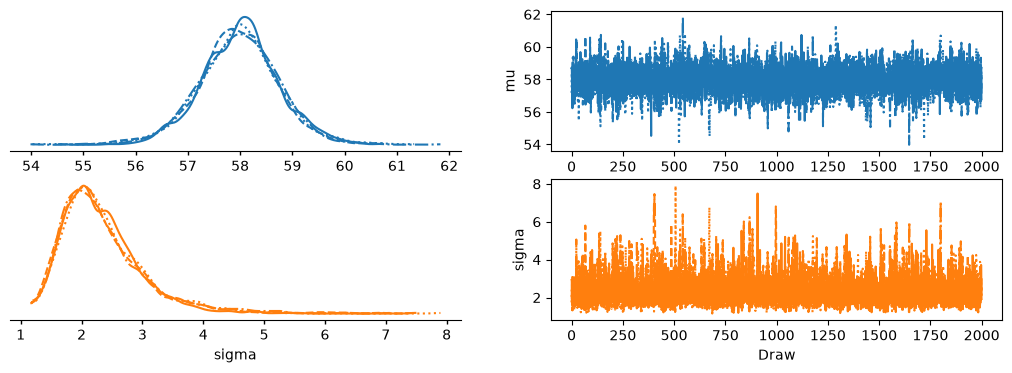

In [31]:
az.plot_trace_dist(idata)
plt.show()

mu: media a posteriori = 57.9791, HDI 95% = [56.4530, 59.4983]
sigma: media a posteriori = 2.3444, HDI 95% = [1.2881, 3.7216]


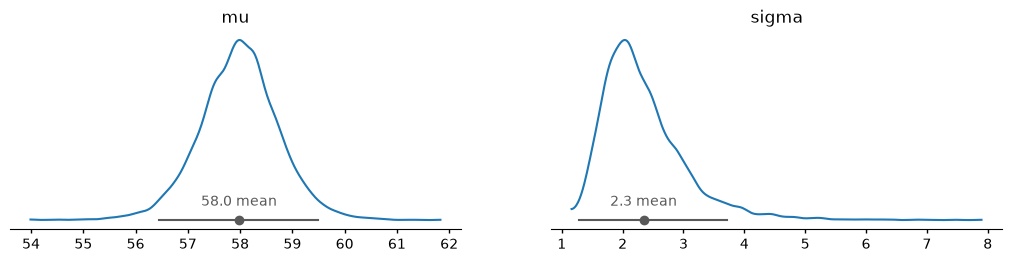

In [32]:
post = idata.posterior
hdi = az.hdi(idata, prob = 0.95)

for var in ["mu", "sigma"]:
    lb, ub = hdi[var].values
    print(f"{var}: media a posteriori = {post[var].mean().item():.4f}, HDI 95% = [{lb:.4f}, {ub:.4f}]")

az.plot_dist(idata, point_estimate = "mean", ci_kind = "hdi", ci_prob = 0.95)
plt.show()

Intervalele HDI 95%:

$$
\mu \in [56.44,\ 59.54] \text{ dB}, \qquad \sigma \in [1.31,\ 3.70] \text{ dB}
$$

Media a posteriori a lui $\mu$ este ≈ 58.02 dB, practic media observaţiilor. Distribuţia lui $\sigma$ este asimetrică, cu coada spre dreapta: $\sigma > 0$, iar cu doar 10 observaţii valorile mari nu pot fi excluse. De aceea media a posteriori a lui $\sigma$ (≈ 2.34) este mai mare decât deviaţia standard a datelor (2).